 ImmoAnalyse : exploration des données traitées

Chargement des données propres (2979 lignes attendues)

In [344]:
import json
import pandas as pd
import matplotlib.pyplot as plt

propres = pd.read_csv("../data/processed/donnees_propres.csv")
print(len(propres))

2979


In [345]:
# 10 lignes prises au hasard
propres.sample(10, random_state=1)

,source,id_local,date,type_transaction,type_bien,region,ville,prix,periodicite,surface,...,statut,prix_propre,surface_propre,type_propre,date_propre,region_propre,ville_propre,doublon_exact,motifs,avertissements
445,import_historique,HIS-0454,2018-04-22,vente,Appartement,Kédougou,Salémata,101 130 000,NaN,98.7,...,NaN,101130000.0,98.7,Appartement,2018-04-22,Kédougou,Salémata,False,NaN,NaN
2687,particuliers,PRT-01837,2018-10-28,vente,Appartement,Fatick,Fatick,52183000,NaN,131.5,...,Vendu,52183000.0,131.5,Appartement,2018-10-28,Fatick,Fatick,False,NaN,NaN
1541,agence_teranga,AGT-01002,17/01/2022,location,Appartement,Matam,Ourossogui,540000,NaN,84.1,...,Loué,540000.0,84.1,Appartement,2022-01-17,Matam,Ourossogui,False,NaN,périodicité du loyer absente
521,plateforme,PLT-00004,2025-01-18,vente,Appartement,Thiès,Joal-Fadiouth,42273000,NaN,69.8,...,En vente,42273000.0,69.8,Appartement,2025-01-18,Thiès,Joal-Fadiouth,False,NaN,NaN
367,import_historique,HIS-0374,26/03/2019,vente,TERRAIN,Matam,Ourossogui,48230000,NaN,1285.2,...,NaN,48230000.0,1285.2,Terrain,2019-03-26,Matam,Ourossogui,False,NaN,NaN
713,plateforme,PLT-00200,2022-08-03,vente,Terrain,Fatick,Kaolack-Fatick,61525000,NaN,418.2,...,En vente,61525000.0,418.2,Terrain,2022-08-03,Fatick,Kaolack-Fatick,False,NaN,NaN
2185,notaires,NOT-02391,2019-11-10,vente,Terrain,Kaolack,Kaolack,84543000.0,NaN,569.3,...,Vendu,84543000.0,569.3,Terrain,2019-11-10,Kaolack,Kaolack,False,NaN,NaN
1156,plateforme,PLT-00649,2022-04-16,vente,Maison,Louga,Kébémer,82168000,NaN,195.4,...,Vendu,82168000.0,195.4,Maison,2022-04-16,Louga,Kébémer,False,NaN,NaN
282,import_historique,HIS-0287,2018-03-07,vente,Terrain,Ziguinchor,Ziguinchor,53433000,NaN,1401.8,...,NaN,53433000.0,1401.8,Terrain,2018-03-07,Ziguinchor,Ziguinchor,False,NaN,NaN
558,plateforme,PLT-00042,2024-06-16,vente,Terrain,Louga,Linguère,83 825 000,NaN,1325.8,...,Vendu,83825000.0,1325.8,Terrain,2024-06-16,Louga,Linguère,False,NaN,NaN


Chargement des lignes rejetées (205 attendues)

In [346]:
quarantaine = pd.read_csv("../data/quarantaine/quarantaine.csv")
print(len(quarantaine))


205



Lecture affichage du rapport de qualité (fichier JSON)

In [347]:
with open("../reports/quality_report.json", encoding="utf-8") as f:
    rapport = json.load(f)

print(rapport.keys())

dict_keys(['enregistrements_recus', 'valeurs_manquantes_par_colonne', 'doublons_exacts', 'taux_doublons_pct', 'erreurs_conversion_par_champ', 'enregistrements_corriges', 'enregistrements_en_quarantaine', 'enregistrements_conserves_avec_avertissement', 'enregistrements_entierement_conformes', 'par_source', 'regles'])


## Exploration des données propres
Structure, types de variables et distributions.

In [348]:
# Nombre de lignes et de colonnes, types des colonnes
propres.info()

<class 'pandas.DataFrame'>
RangeIndex: 2979 entries, 0 to 2978
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   source            2979 non-null   str    
 1   id_local          2979 non-null   str    
 2   date              2979 non-null   str    
 3   type_transaction  2979 non-null   str    
 4   type_bien         2979 non-null   str    
 5   region            2979 non-null   str    
 6   ville             2971 non-null   str    
 7   prix              2979 non-null   str    
 8   periodicite       171 non-null    str    
 9   surface           2979 non-null   str    
 10  chambres          2979 non-null   int64  
 11  salles_bain       2589 non-null   float64
 12  statut            2461 non-null   str    
 13  prix_propre       2979 non-null   float64
 14  surface_propre    2979 non-null   float64
 15  type_propre       2979 non-null   str    
 16  date_propre       2979 non-null   str    
 17  region

statistiques des variables numériques 

In [349]:
# Résumé : min, médiane, max, etc.
propres[["prix_propre", "surface_propre", "chambres", "salles_bain"]].describe()

,prix_propre,surface_propre,chambres,salles_bain
count,2.979000e+03,2979.000000,2979.000000,2589.000000
mean,8.891159e+07,240.692011,2.820074,1.935883
std,9.796782e+07,292.333268,2.108026,1.447077
min,4.000000e+04,10.200000,0.000000,0.000000
25%,2.265700e+07,71.850000,1.000000,1.000000
50%,5.977900e+07,147.000000,3.000000,2.000000
75%,1.161500e+08,246.400000,5.000000,3.000000
max,5.675590e+08,1494.800000,6.000000,4.000000


répartition des types de biens

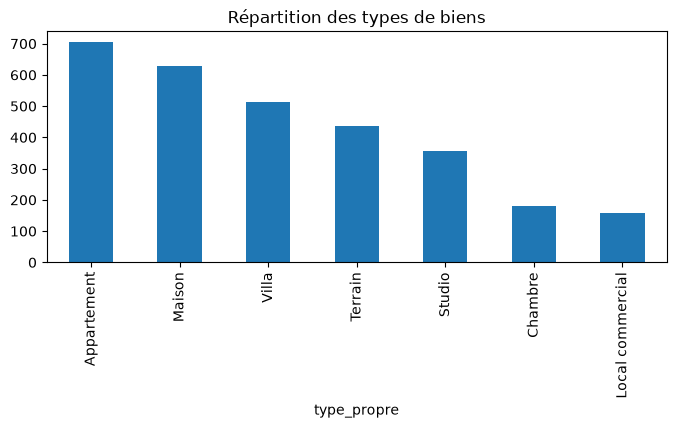

In [350]:
# Distribution des types de biens
propres["type_propre"].value_counts().plot(kind="bar", figsize=(8, 3))
plt.title("Répartition des types de biens")
plt.show()

répartition par région

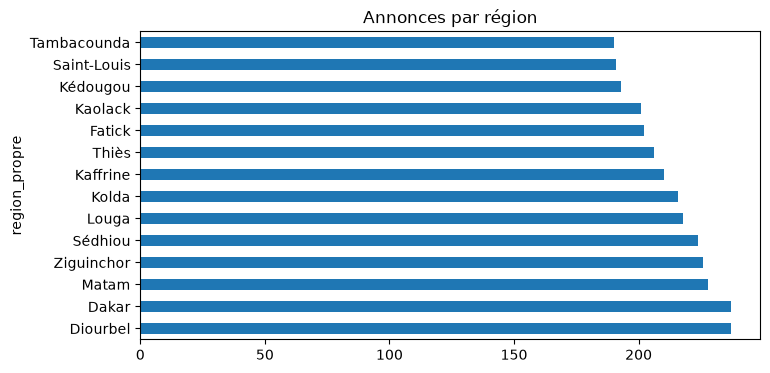

In [351]:
# Distribution par région
propres["region_propre"].value_counts().plot(kind="barh", figsize=(8, 4))
plt.title("Annonces par région")
plt.show()

distribution de la surface

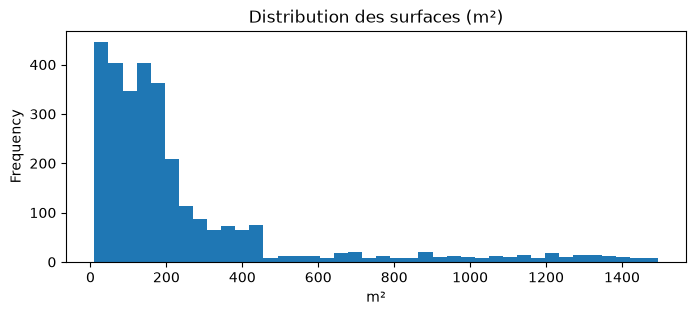

In [352]:
# Histogramme de la surface
propres["surface_propre"].plot(kind="hist", bins=40, figsize=(8, 3))
plt.title("Distribution des surfaces (m²)")
plt.xlabel("m²")
plt.show()

distribution des prix de vente

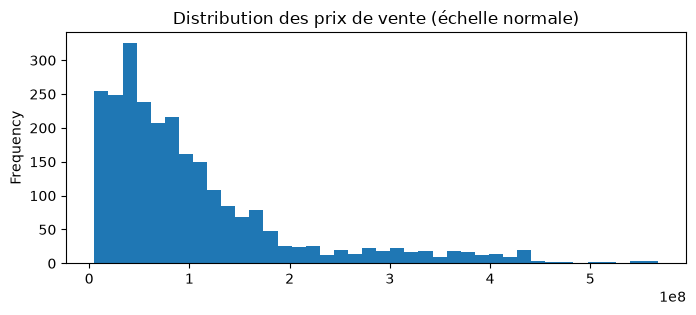

In [353]:
# Même données, sans logarithme
ventes["prix_propre"].plot(kind="hist", bins=40, figsize=(8, 3))
plt.title("Distribution des prix de vente (échelle normale)")
plt.show()

 Qualité par source
Pour chaque source : lignes reçues, conservées, rejetées.

In [354]:
# Tableau de qualité : une ligne par source
par_source = pd.DataFrame(rapport["par_source"]).T
par_source

,0,1,2,3,4
source,agence_teranga,import_historique,notaires,particuliers,plateforme
recus,640,528,410,731,875
propres,631,518,390,595,845
quarantaine,9,10,20,136,30
avec_avertissement,126,69,0,199,36


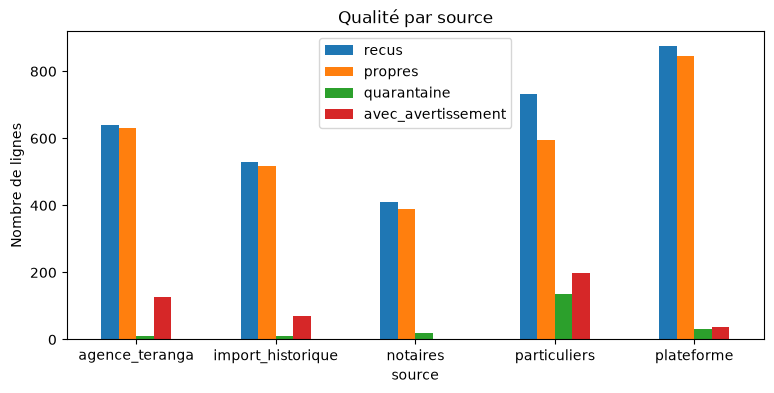

In [355]:
# Tableau : une ligne par source, avec le nom de la source comme index
par_source = pd.DataFrame(rapport["par_source"])
par_source = par_source.set_index("source")
par_source = par_source.apply(pd.to_numeric, errors="coerce")

# Graphique : une couleur par indicateur, une barre par source
par_source[["recus", "propres", "quarantaine", "avec_avertissement"]].plot(kind="bar", figsize=(9, 4))
plt.title("Qualité par source")
plt.ylabel("Nombre de lignes")
plt.xticks(rotation=0)
plt.show()

 Une ligne peut avoir plusieurs motifs : on les sépare, puis on compte

In [356]:
motifs = quarantaine["motifs"].str.split("; ").explode()
motifs.value_counts()

motifs
prix absent ou invalide        98
surface absente ou invalide    88
doublon exact                  15
date impossible                 6
date future                     5
Name: count, dtype: int64

Graphique horizontal des motifs

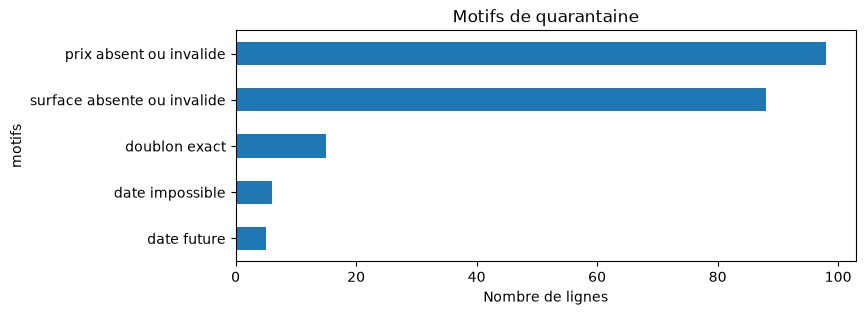

In [357]:
motifs.value_counts().sort_values().plot(kind="barh", figsize=(8, 3))
plt.title("Motifs de quarantaine")
plt.xlabel("Nombre de lignes")
plt.show()

Comparaison du prix au m² par type de bien (ventes uniquement).

In [358]:
# On garde seulement les ventes (un loyer n'est pas comparable à un prix de vente)
ventes = propres[propres["type_transaction"] == "vente"].copy()

# Prix au m² = prix nettoyé divisé par la surface nettoyée
ventes["prix_m2"] = ventes["prix_propre"] / ventes["surface_propre"]

len(ventes)

2530

Médiane du prix au m² pour chaque type de bien

In [359]:
mediane = ventes.groupby("type_propre")["prix_m2"].median().sort_values()
mediane

type_propre
Terrain              64764.926823
Chambre             571791.907514
Local commercial    625690.717678
Appartement         656660.703637
Maison              670301.314365
Studio              748130.576320
Villa               906133.254824
Name: prix_m2, dtype: float64

Graphique de la médiane par type

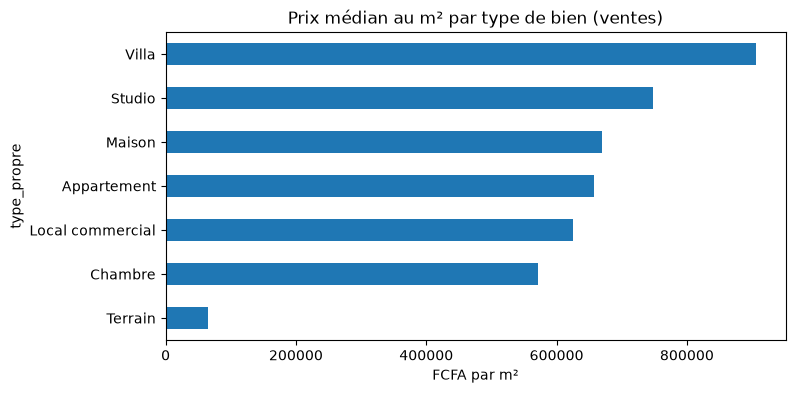

In [360]:
mediane.plot(kind="barh", figsize=(8, 4))
plt.title("Prix médian au m² par type de bien (ventes)")
plt.xlabel("FCFA par m²")
plt.show()

Taux de conformité par règle
Conformité = lignes conformes / lignes évaluables.

In [361]:
# Une ligne par règle métier
regles = pd.DataFrame(rapport["regles"])
regles

,regle,evaluables,non_evaluables,conformes,non_conformes,taux_conformite_pct
0,identifiant présent,3184,0,3184,0,100.00
1,transaction valide,3184,0,3184,0,100.00
2,prix valide,3109,75,3086,23,99.26
3,surface valide,3104,80,3096,8,99.74
4,date valide et non future,3184,0,3173,11,99.65
5,type dans le référentiel,3184,0,3184,0,100.00


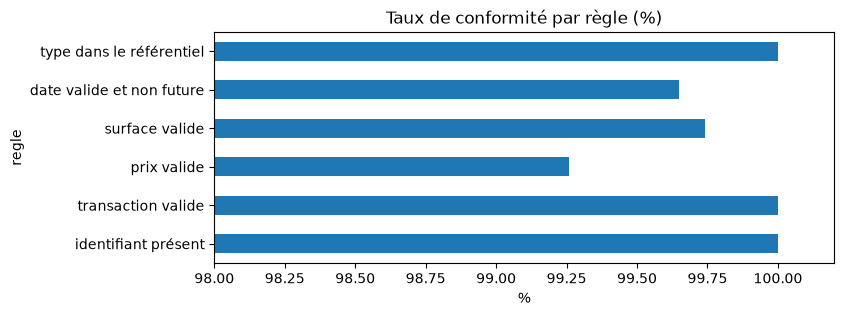

In [362]:
#Graphique des taux de conformité (axe zoomé entre 98 et 100 %)
regles.set_index("regle")["taux_conformite_pct"].plot(kind="barh", figsize=(8, 3))
plt.xlim(98, 100.2)
plt.title("Taux de conformité par règle (%)")
plt.xlabel("%")
plt.show()

## Conclusions

### Qualité des données
- 3184 annonces reçues de 5 sources : 2979 conservées, 205 en quarantaine.
- ...

### Anomalies
- Motif de rejet principal : ...
- Avertissement le plus fréquent : ...

### Prix et marché
- Prix au m² médian le plus élevé : ...
- Prix au m² médian le plus bas : ...

### Limites
- ...